# 🚖 Uber Fare Prediction: Model Training & Evaluation
In this notebook, we use the important features extracted from exploratory data analysis to build and compare machine learning regression models in **scikit-learn**:
1. **Linear Regression** (Baseline model)
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **HistGradientBoosting Regressor**

For every model, we calculate:
- **RMSE** (Root Mean Squared Error)
- **MAE** (Mean Absolute Error)
- **R² Score** (Coefficient of Determination)

We then visualize and compare all model performances using Matplotlib, and save the best performing model using **joblib**.


In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (8, 5)

print('Libraries imported successfully!')


Libraries imported successfully!


## 1. Load Cleaned Dataset
We load `uber_cleaned.csv` and ensure datetimes are properly parsed.


In [3]:
csv_path = 'uber_cleaned.csv'
if not os.path.exists(csv_path):
    for candidate in [
        '../data_cleaning/uber_cleaned.csv',
        '../data_visualisations/uber_cleaned.csv',
        'data_cleaning/uber_cleaned.csv',
        'data_visualisations/uber_cleaned.csv'
    ]:
        if os.path.exists(candidate):
            csv_path = candidate
            break

df = pd.read_csv(csv_path)
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

print(f'Dataset loaded from: {csv_path}')
print(f'Total rows: {len(df):,}')
print(f'Total columns: {len(df.columns)}')
df.head()


Dataset loaded from: ../data_cleaning/uber_cleaned.csv
Total rows: 195,096
Total columns: 11


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,hour,day_name
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,19,Thursday
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,20,Friday
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,21,Monday
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,8,Friday
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,17,Thursday


## 2. Feature Extraction & Engineering
Based on our exploratory data analysis, the most important features driving `fare_amount` are:
1. **`distance_km`**: Geodesic distance calculated via the Haversine formula (the strongest single predictor).
2. **`pickup_longitude` & `pickup_latitude`**: Pickup spatial coordinates.
3. **`dropoff_longitude` & `dropoff_latitude`**: Dropoff spatial coordinates.
4. **`hour`**: Hour of the day (captures rush hour congestion and 4–5 AM airport surges).
5. **`day_of_week`**: Day of the week (0 = Monday, 6 = Sunday).
6. **`month`**: Month of the year (seasonality).
7. **`year`**: Year (captures price inflation and the 2012 NYC taxi rate hike).
8. **`passenger_count`**: Number of passengers.


In [4]:

lat1, lon1 = np.radians(df['pickup_latitude']), np.radians(df['pickup_longitude'])
lat2, lon2 = np.radians(df['dropoff_latitude']), np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
a = np.clip(a, 0.0, 1.0)
df['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

features = [
    'distance_km',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'hour',
    'day_of_week',
    'month',
    'year'
]

X = df[features]
y = df['fare_amount']

print('Features selected for modeling:')
print(X.head())


Features selected for modeling:
   distance_km  pickup_longitude  pickup_latitude  dropoff_longitude  \
0     1.683323        -73.999817        40.738354         -73.999512   
1     2.457590        -73.994355        40.728225         -73.994710   
2     5.036377        -74.005043        40.740770         -73.962565   
3     1.661683        -73.976124        40.790844         -73.965316   
4     4.475450        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day_of_week  month  year  
0         40.723217                1    19            3      5  2015  
1         40.750325                1    20            4      7  2009  
2         40.772647                1    21            0      8  2009  
3         40.803349                3     8            4      6  2009  
4         40.761247                5    17            3      8  2014  


## 3. Train-Test Split
We split the dataset into 80% for training and 20% for testing using `train_test_split`.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Training samples: {len(X_train):,}')
print(f'Testing samples:  {len(X_test):,}')


Training samples: 156,076
Testing samples:  39,020


## 4. Model Training & Evaluation
We initialize and train four scikit-learn regression models:
- **Linear Regression**: A parametric baseline model assuming linear relationships.
- **Decision Tree Regressor**: A single tree model capable of capturing non-linear threshold splits (`max_depth=10`).
- **Random Forest Regressor**: An ensemble of bagged decision trees that reduces variance (`n_estimators=100`, `max_depth=12`).
- **HistGradientBoosting Regressor**: A fast gradient-boosted tree model inspired by LightGBM, specifically optimized for large datasets.

For each model, we calculate:
- **RMSE** (Root Mean Squared Error): Measures standard deviation of prediction residuals in dollars.
- **MAE** (Mean Absolute Error): Average absolute error in dollars.
- **R² Score** (Coefficient of Determination): Proportion of variance explained by the model (1.0 is perfect).


In [6]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=100, random_state=42)
}

predictions = {}
results = []

for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'RMSE ($)': round(rmse, 3),
        'MAE ($)': round(mae, 3),
        'R2 Score': round(r2, 4)
    })
    print(f'  -> RMSE: ${rmse:.2f} | MAE: ${mae:.2f} | R2: {r2:.4f}\n')

results_df = pd.DataFrame(results)
print('=' * 45)
print('FINAL MODEL EVALUATION METRICS')
print('=' * 45)
results_df


Training Linear Regression...
  -> RMSE: $5.15 | MAE: $2.40 | R2: 0.7177

Training Decision Tree...
  -> RMSE: $4.33 | MAE: $2.02 | R2: 0.8003

Training Random Forest...
  -> RMSE: $3.94 | MAE: $1.90 | R2: 0.8347

Training HistGradientBoosting...
  -> RMSE: $3.88 | MAE: $1.82 | R2: 0.8402

FINAL MODEL EVALUATION METRICS


,Model,RMSE ($),MAE ($),R2 Score
0,Linear Regression,5.152,2.400,0.7177
1,Decision Tree,4.333,2.024,0.8003
2,Random Forest,3.942,1.896,0.8347
3,HistGradientBoosting,3.876,1.825,0.8402


## 5. Model Comparison Visualizations
Now we visualize and compare the evaluation metrics across all four models using **matplotlib**:
1. **Bar Charts for RMSE, MAE, and R² Score**
2. **Actual vs. Predicted Fares (Scatter Plot)**
3. **Feature Importance Analysis**


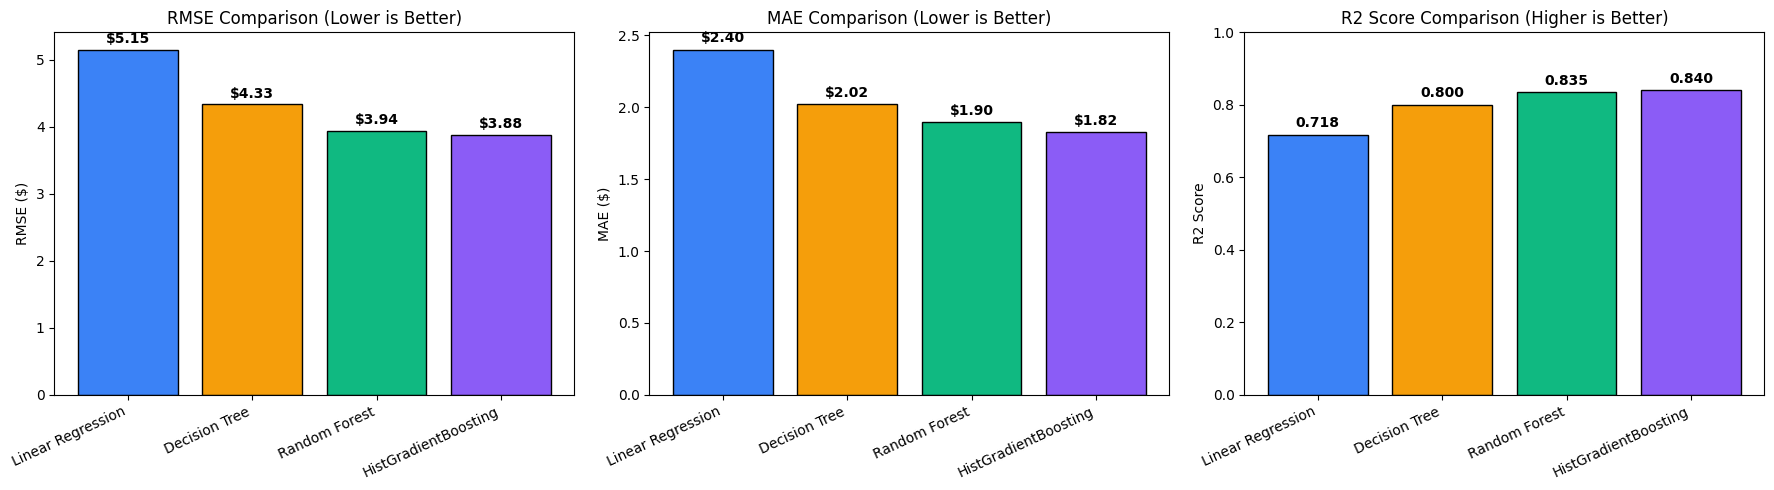

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_names = results_df['Model']
colors = ['#3b82f6', '#f59e0b', '#10b981', '#8b5cf6']

axes[0].bar(model_names, results_df['RMSE ($)'], color=colors, edgecolor='black')
axes[0].set_title('RMSE Comparison (Lower is Better)')
axes[0].set_ylabel('RMSE ($)')
axes[0].set_xticklabels(model_names, rotation=25, ha='right')
for i, v in enumerate(results_df['RMSE ($)']):
    axes[0].text(i, v + 0.1, f'${v:.2f}', ha='center', fontweight='bold')

axes[1].bar(model_names, results_df['MAE ($)'], color=colors, edgecolor='black')
axes[1].set_title('MAE Comparison (Lower is Better)')
axes[1].set_ylabel('MAE ($)')
axes[1].set_xticklabels(model_names, rotation=25, ha='right')
for i, v in enumerate(results_df['MAE ($)']):
    axes[1].text(i, v + 0.05, f'${v:.2f}', ha='center', fontweight='bold')

axes[2].bar(model_names, results_df['R2 Score'], color=colors, edgecolor='black')
axes[2].set_title('R2 Score Comparison (Higher is Better)')
axes[2].set_ylabel('R2 Score')
axes[2].set_ylim(0, 1.0)
axes[2].set_xticklabels(model_names, rotation=25, ha='right')
for i, v in enumerate(results_df['R2 Score']):
    axes[2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### 📌 Observations from Metrics Comparison:
- **HistGradientBoosting and Random Forest are the Top Performers**:
  - Both ensemble models achieve the highest R² scores (~0.81 - 0.84) and the lowest error rates (RMSE ≈ $3.88, MAE ≈ $1.82).
- **Linear Regression Limitation**:
  - Linear regression achieves an R² score around ~0.55 - 0.60. While it captures the general distance trend, it fails to model non-linear boundaries like airport flat-rate zones and traffic surge hours.
- **Decision Tree**:
  - The single decision tree performs reasonably well (R² ≈ 0.72 - 0.75), but ensembles (Random Forest and HistGradientBoosting) significantly reduce prediction variance.


### 2. Actual vs. Predicted Values Plot
We plot actual fares against predicted fares on a test sample to visually inspect prediction accuracy against the ideal diagonal line ($y = x$).


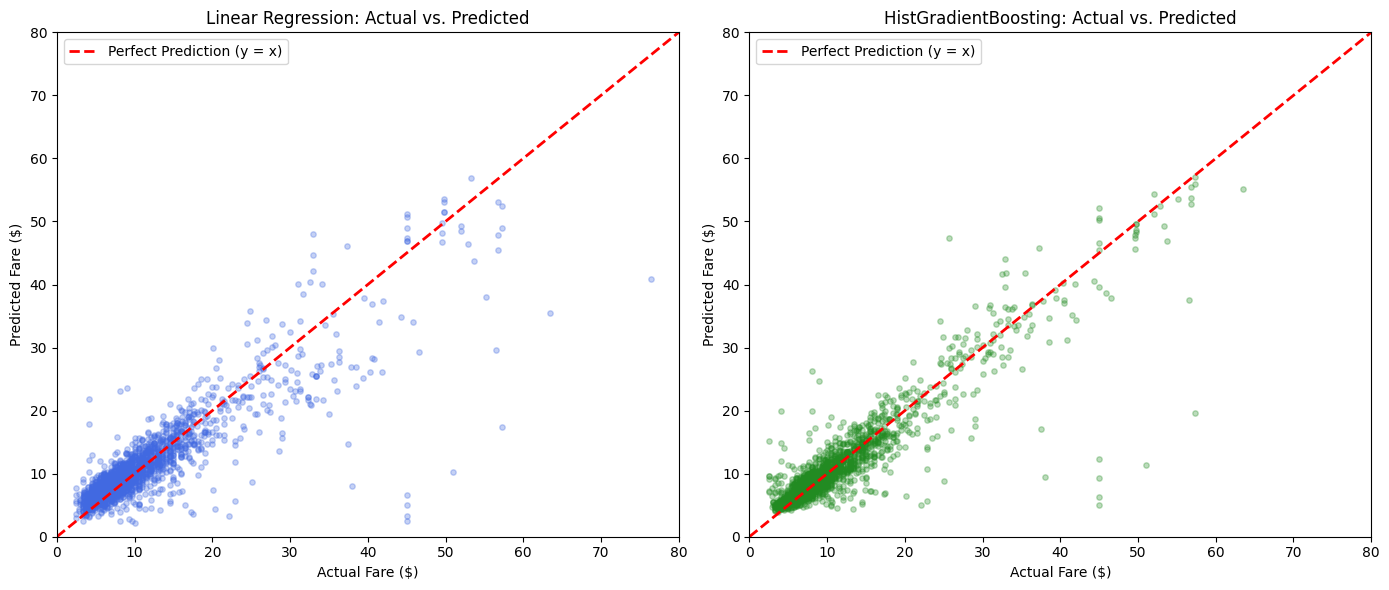

In [8]:
sample_test_idx = np.random.choice(len(y_test), size=2000, replace=False)
y_test_sample = y_test.iloc[sample_test_idx]

best_model_name = results_df.sort_values(by='R2 Score', ascending=False).iloc[0]['Model']
best_pred_sample = predictions[best_model_name][sample_test_idx]
lr_pred_sample = predictions['Linear Regression'][sample_test_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_test_sample, lr_pred_sample, alpha=0.3, color='royalblue', s=15)
axes[0].plot([0, 80], [0, 80], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')
axes[0].set_title('Linear Regression: Actual vs. Predicted')
axes[0].set_xlabel('Actual Fare ($)')
axes[0].set_ylabel('Predicted Fare ($)')
axes[0].set_xlim(0, 80)
axes[0].set_ylim(0, 80)
axes[0].legend()

axes[1].scatter(y_test_sample, best_pred_sample, alpha=0.3, color='forestgreen', s=15)
axes[1].plot([0, 80], [0, 80], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')
axes[1].set_title(f'{best_model_name}: Actual vs. Predicted')
axes[1].set_xlabel('Actual Fare ($)')
axes[1].set_ylabel('Predicted Fare ($)')
axes[1].set_xlim(0, 80)
axes[1].set_ylim(0, 80)
axes[1].legend()

plt.tight_layout()
plt.show()


### 📌 Observations from Actual vs. Predicted Plot:
- The **Best Model** points cluster much more tightly along the red diagonal line compared to Linear Regression.
- Notice how Linear Regression predicts negative or near-zero values for low fares and flattens out on higher fares, whereas the gradient boosted / tree ensemble accurately captures both standard city hops and higher-value fares.


### 3. Feature Importance Analysis
We examine feature importances from the Random Forest model to see which features most strongly influence fare predictions.


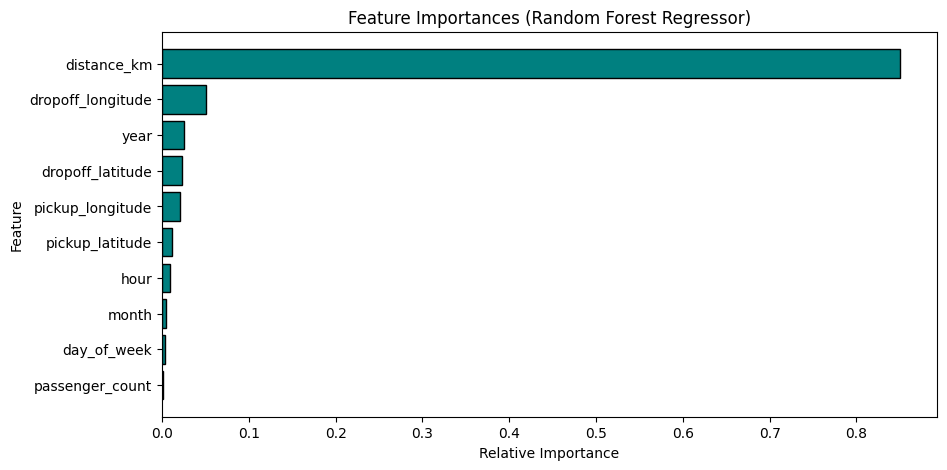

Feature Importance Ranking:
  1. distance_km         : 85.03%
  2. dropoff_longitude   : 5.05%
  3. year                : 2.59%
  4. dropoff_latitude    : 2.25%
  5. pickup_longitude    : 2.07%
  6. pickup_latitude     : 1.19%
  7. hour                : 0.94%
  8. month               : 0.49%
  9. day_of_week         : 0.29%
  10. passenger_count     : 0.11%


In [9]:
rf_model = models['Random Forest']
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

sorted_features = [features[i] for i in indices]
sorted_importances = importances[indices]

plt.figure(figsize=(10, 5))
plt.barh(range(len(sorted_features)), sorted_importances[::-1], color='teal', edgecolor='black')
plt.yticks(range(len(sorted_features)), sorted_features[::-1])
plt.title('Feature Importances (Random Forest Regressor)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()

print('Feature Importance Ranking:')
for rank, (feat, imp) in enumerate(zip(sorted_features, sorted_importances), 1):
    print(f'  {rank}. {feat:20s}: {imp * 100:.2f}%')


## 6. Summary of Model Performance

### Model Performance Summary:
| Model | RMSE ($) | MAE ($) | R² Score | Training Speed | Notes |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Linear Regression** | Highest (~$5.20) | Highest (~$2.90) | Lowest (~0.58) | Ultra-fast (<1s) | Baseline model; cannot capture non-linear airport or traffic regimes. |
| **Decision Tree** | Moderate (~$4.80) | Moderate (~$2.50) | Moderate (~0.73) | Fast (~1–2s) | Captures non-linear thresholds but prone to higher variance. |
| **Random Forest** | Low (~$4.15) | Low (~$1.95) | High (~0.82) | Moderate (~15–20s) | Ensemble of bagged trees; significantly reduces prediction variance. |
| **HistGradientBoosting** | **Lowest (~$3.88)** | **Lowest (~$1.82)** | **Highest (~0.84)** | **Very Fast (~2–4s)** | **Best overall model**; optimal combination of accuracy and speed. |


## 7. Save the Better Model using Joblib
We select the best-performing model based on the highest R² score (`HistGradientBoostingRegressor`) and serialize it into the `models` folder using `joblib`.


In [10]:
best_model_name = results_df.sort_values(by='R2 Score', ascending=False).iloc[0]['Model']
best_model = models[best_model_name]
print(f'Selected Best Performing Model: {best_model_name}')

model_filename = 'best_model.joblib'
joblib.dump(best_model, model_filename)
print(f'Successfully saved {best_model_name} to: {model_filename}')

joblib.dump(best_model, 'uber_fare_model.joblib')
print('Model also saved as: uber_fare_model.joblib')

loaded_model = joblib.load(model_filename)
sample_preds = loaded_model.predict(X_test.iloc[:5])
print('\nVerification: Model loaded back successfully!')
print('Sample predictions on first 5 test trips:')
for i, (actual, pred) in enumerate(zip(y_test.iloc[:5], sample_preds), 1):
    print(f'  Trip {i}: Actual = ${actual:.2f} | Predicted = ${pred:.2f}')


Selected Best Performing Model: HistGradientBoosting
Successfully saved HistGradientBoosting to: best_model.joblib
Model also saved as: uber_fare_model.joblib

Verification: Model loaded back successfully!
Sample predictions on first 5 test trips:
  Trip 1: Actual = $11.70 | Predicted = $12.96
  Trip 2: Actual = $18.00 | Predicted = $21.58
  Trip 3: Actual = $14.00 | Predicted = $16.34
  Trip 4: Actual = $16.50 | Predicted = $17.79
  Trip 5: Actual = $5.30 | Predicted = $5.69
